   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 10.3 MB/s eta 0:00:00
--- TESTE DE EXTREMOS ---
Resultado (0,0): 11.00% (Esperado 0%)
Resultado (100,10): 91.67% (Esperado 100%)

Artefato salvo: 'superficie_decisao.png'


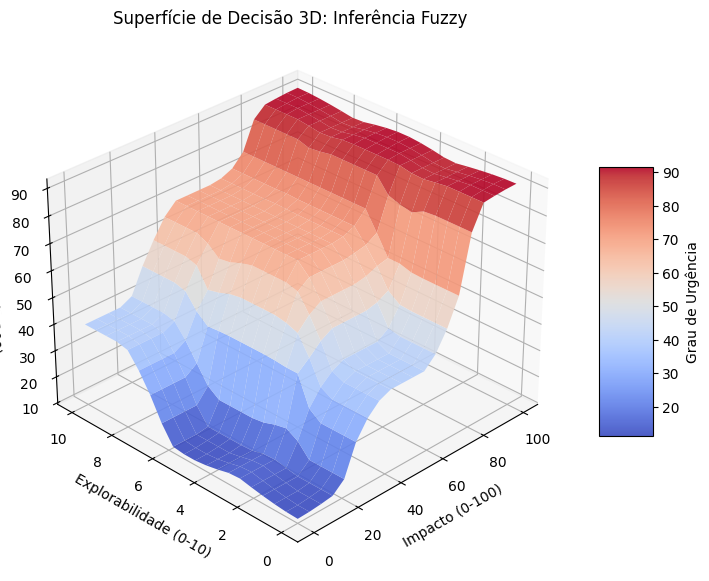

In [ ]:
!pip install scikit-fuzzy -q

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ====================================================================
# 1. DECLARAÇÃO DO UNIVERSO DE DISCURSO
# ====================================================================
impacto = ctrl.Antecedent(np.arange(0, 101, 1), 'impacto')
explorabilidade = ctrl.Antecedent(np.arange(0, 11, 1), 'explorabilidade')
urgencia = ctrl.Consequent(np.arange(0, 101, 1), 'urgencia')

# ====================================================================
# 2. FUNÇÕES DE PERTINÊNCIA (MEMBERSHIP FUNCTIONS)
# ====================================================================
# Antecedente: Impacto
imparto_baixo = fuzz.trimf(impacto.universe, [0, 0, 40])
impacto['baixo'] = imparto_baixo
impacto['medio'] = fuzz.trimf(impacto.universe, [20, 50, 80])
impacto['alto'] = fuzz.trimf(impacto.universe, [60, 100, 100])

# Antecedente: Explorabilidade
explorabilidade['baixa'] = fuzz.trimf(explorabilidade.universe, [0, 0, 4])
explorabilidade['moderada'] = fuzz.trimf(explorabilidade.universe, [2, 5, 8])
explorabilidade['alta'] = fuzz.trimf(explorabilidade.universe, [6, 10, 10])

# Consequente: Urgência
urgencia['baixa'] = fuzz.trimf(urgencia.universe, [0, 0, 33])
urgencia['media'] = fuzz.trimf(urgencia.universe, [15, 40, 65])
urgencia['alta'] = fuzz.trimf(urgencia.universe, [45, 70, 95])
# OBS: O padrão é triângulo (trimf). Para testar a abordagem B do desafio,
# você poderia alterar a linha abaixo para trapmf: [75, 90, 100, 100]
urgencia['critica'] = fuzz.trimf(urgencia.universe, [75, 100, 100])

# Defuzzificação padrão: 'centroid'. Para testar a abordagem MOM:
# urgencia.defuzzify_method = 'mom'

# ====================================================================
# 3. BASE DE REGRAS MAMDANI (3x3 = 9 Regras)
# ====================================================================
regra1 = ctrl.Rule(impacto['baixo'] & explorabilidade['baixa'], urgencia['baixa'])
regra2 = ctrl.Rule(impacto['baixo'] & explorabilidade['moderada'], urgencia['baixa'])
regra3 = ctrl.Rule(impacto['baixo'] & explorabilidade['alta'], urgencia['media'])

regra4 = ctrl.Rule(impacto['medio'] & explorabilidade['baixa'], urgencia['media'])
regra5 = ctrl.Rule(impacto['medio'] & explorabilidade['moderada'], urgencia['alta'])
regra6 = ctrl.Rule(impacto['medio'] & explorabilidade['alta'], urgencia['alta'])

regra7 = ctrl.Rule(impacto['alto'] & explorabilidade['baixa'], urgencia['critica'])
regra8 = ctrl.Rule(impacto['alto'] & explorabilidade['moderada'], urgencia['critica'])
regra9 = ctrl.Rule(impacto['alto'] & explorabilidade['alta'], urgencia['critica'])

# ====================================================================
# 4. CRIAÇÃO DO SISTEMA DE CONTROLE
# ====================================================================
sistema_urgencia = ctrl.ControlSystem([
    regra1, regra2, regra3, regra4, regra5, regra6, regra7, regra8, regra9
])
simulador = ctrl.ControlSystemSimulation(sistema_urgencia)

# ====================================================================
# 5. TESTANDO OS EXTREMOS (PROVA DO DESAFIO)
# ====================================================================
print("--- TESTE DE EXTREMOS ---")
simulador.input['impacto'] = 0
simulador.input['explorabilidade'] = 0
simulador.compute()
print(f"Resultado (0,0): {simulador.output['urgencia']:.2f}% (Esperado 0%)")

simulador.input['impacto'] = 100
simulador.input['explorabilidade'] = 10
simulador.compute()
print(f"Resultado (100,10): {simulador.output['urgencia']:.2f}% (Esperado 100%)")

# ====================================================================
# 6. GERAÇÃO DA SUPERFÍCIE DE DECISÃO 3D
# ====================================================================
# Criando a malha de eixos (Meshgrid)
x_impacto = np.linspace(0, 100, 20)
y_explorab = np.linspace(0, 10, 20)
x_impacto, y_explorab = np.meshgrid(x_impacto, y_explorab)
z_urgencia = np.zeros_like(x_impacto)

# Simulando todos os pontos da malha para encontrar a matriz Z
for i in range(20):
    for j in range(20):
        simulador.input['impacto'] = x_impacto[i, j]
        simulador.input['explorabilidade'] = y_explorab[i, j]
        simulador.compute()
        z_urgencia[i, j] = simulador.output['urgencia']

# Plotando a superfície
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(x_impacto, y_explorab, z_urgencia, cmap='coolwarm',
                       linewidth=0, antialiased=True, alpha=0.9)

ax.set_title('Superfície de Decisão 3D: Inferência Fuzzy')
ax.set_xlabel('Impacto (0-100)')
ax.set_ylabel('Explorabilidade (0-10)')
ax.set_zlabel('Urgência (0-100)')
ax.view_init(elev=30, azim=225) # Ajuste do ângulo de visão
fig.colorbar(surf, shrink=0.5, aspect=5, label='Grau de Urgência')

# Salvando a imagem na raiz do diretório AULA_10
plt.savefig('superficie_decisao.png', dpi=300, bbox_inches='tight')
print("\nArtefato salvo: 'superficie_decisao.png'")
plt.show()